# 15.1 - Binary gingival data preparation

D2 Mendeley 3253gj88rr v1. Convert the audited three-grade gingival regions into one visible-inflammation target. Preserve original image geometry and locked group membership. Test images are not opened.

## 1. Verify the locked source
Read the existing audited manifest and checksum. Only training and validation records enter this derived task.

In [1]:
from pathlib import Path
import json, hashlib, shutil
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
root = Path.cwd()
while not (root / 'pyproject.toml').exists():
    if root == root.parent: raise RuntimeError('Project root unavailable')
    root = root.parent
source_manifest = root / 'data/manifests/gum.splits.csv'
lock = json.loads((root / 'data/manifests/gum.lock.json').read_text())
assert hashlib.sha256(source_manifest.read_bytes()).hexdigest() == lock['splits_sha256']
frame = pd.read_csv(source_manifest)
frame = frame[frame.split.isin(['train', 'val'])].copy()
assert len(frame) == 907
assert set(frame[frame.split == 'train'].group_id).isdisjoint(frame[frame.split == 'val'].group_id)
target = root / 'data/processed/gum_binary_v1'
report = root / 'docs/reports/gingivitis_binary'
report.mkdir(parents=True, exist_ok=True)
display(frame.groupby('split').size().rename('Images'))

split
train    747
val      160
Name: Images, dtype: int64

## 2. Merge positive grades
Prepared class 1 (mild) and class 2 (marked) map to target 0. Prepared class 0 supplies source-annotated background. Original jaw classes were already removed by the audited pipeline. Empty files only indicate no positive among source-annotated gingival regions; clinical review of annotation completeness remains pending.

,images,positive_boxes,annotation_negative_images
split,,,
train,747,8759,0
val,160,1871,0


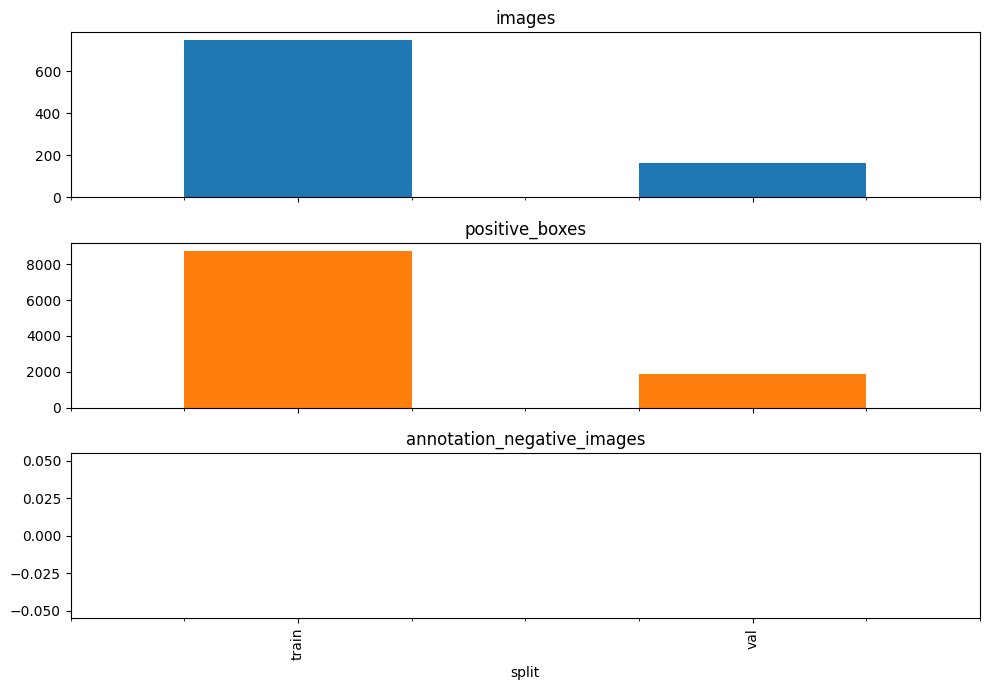

Manifest checksum 5c2b9ceb917e88d2ebff07719105b01dd9c1c46076bca2671879cc39475776f0


In [2]:
records = []
for row in frame.itertuples():
    image, label = root / row.image, root / row.label
    assert hashlib.sha256(image.read_bytes()).hexdigest() == row.sha256
    assert hashlib.sha256(label.read_bytes()).hexdigest() == row.label_sha256
    positive, healthy = [], 0
    for line in label.read_text().splitlines():
        values = list(map(float, line.split()))
        assert len(values) == 5 and values[0] in [0,1,2]
        cls, x, y, w, h = values
        assert w > 0 and h > 0 and 0 <= x-w/2 <= x+w/2 <= 1 and 0 <= y-h/2 <= y+h/2 <= 1
        if cls == 0: healthy += 1
        else: positive.append('0 ' + ' '.join(line.split()[1:]))
    assert positive or healthy, 'No source gingival annotations'
    # An empty target file means all SOURCE-ANNOTATED gingival regions are grade 0.
    # It does not certify complete clinical health or exhaustive source coverage.
    for kind in ['images','labels']: (target / kind / row.split).mkdir(parents=True,exist_ok=True)
    shutil.copyfile(image, target / 'images' / row.split / image.name)
    output = target / 'labels' / row.split / label.name
    output.write_text('\n'.join(positive) + ('\n' if positive else ''))
    records.append(dict(sample_id=row.sample_id, split=row.split, group_id=row.group_id,
        image_sha256=row.sha256, source_label_sha256=row.label_sha256,
        binary_label_sha256=hashlib.sha256(output.read_bytes()).hexdigest(),
        positives=len(positive), source_grade0_regions=healthy,
        annotation_negative=not bool(positive)))
summary = pd.DataFrame(records)
summary.to_csv(report / 'manifest.csv',index=False)
(target / 'data.yaml').write_text('train: images/train\nval: images/val\nnames:\n  0: visible_gingival_inflammation\n')
counts=summary.groupby('split').agg(images=('sample_id','size'), positive_boxes=('positives','sum'), annotation_negative_images=('annotation_negative','sum'))
display(counts)
counts.plot.bar(subplots=True, figsize=(10,7),legend=False); plt.tight_layout(); plt.show()
print('Manifest checksum',hashlib.sha256((report/'manifest.csv').read_bytes()).hexdigest())

## 3. Inspect bounding boxes
Use seeded training images to inspect gingival-region geometry. The target is a region-level visual finding.

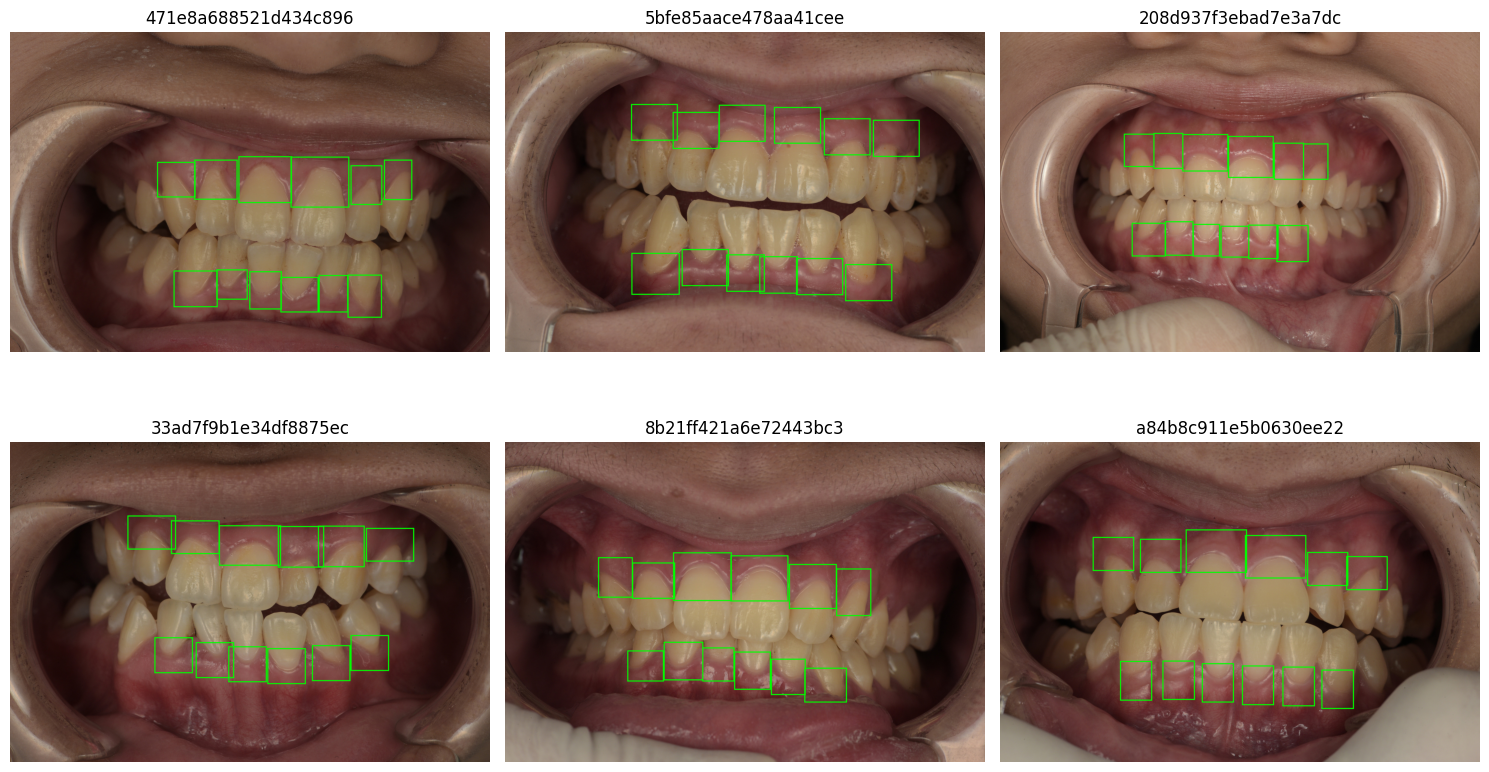

In [3]:
fig, axes = plt.subplots(2,3,figsize=(15,9))
for ax, row in zip(axes.flat, frame[frame.split=='train'].sample(6,random_state=42).itertuples()):
    im=Image.open(root / row.image).convert('RGB'); draw=ImageDraw.Draw(im)
    for line in (target/'labels/train'/Path(row.label).name).read_text().splitlines():
        _,x,y,w,h=map(float,line.split())
        draw.rectangle(((x-w/2)*im.width,(y-h/2)*im.height,(x+w/2)*im.width,(y+h/2)*im.height),outline='lime',width=3)
    ax.imshow(im); ax.set_title(row.sample_id); ax.axis('off')
plt.tight_layout(); plt.savefig(report/'binary_overlays.png',dpi=130); plt.show()